# 04 – Robustness checks

**Purpose:** test how far the Stage 3 result (ML beats the profile baseline and the fixed timetable) can be trusted, and where the model fails. Feeds report Sections 5 (validation) and 6 (limitations), and the runtime analysis required by the brief.

| # | Question | Section |
|---|---|---|
| 1 | Is the ML gain real or luck? | bootstrap, day-by-day wins |
| 2 | Does it hold every month? | per-month results (Figure 6) |
| 3 | Does it hold when retrained monthly? | walk-forward validation |
| 4 | Does a different model or seed change things? | random forest, seeds |
| 5 | Which inputs are needed? | input removal |
| 6 | Which switch-on threshold is best? | threshold trade-off (Figure 7) |
| 7 | How much history is needed? | training-data amount |
| 8 | Does it work in a room it has never seen? | leave-one-space-out |
| 9 | Where does it go wrong? | bias by hour (Figure 8), holidays, events, sensor gaps |
| 10 | What if missing hours were empty? | missing-as-empty |
| 11 | What does forecasting only one hour ahead gain? | hour-ahead comparison |
| 12 | How fast is it? | timing and profiling |

Unless stated otherwise, models learn from data before 2025 and are scored on the 2025 validation period. The 2026 test period is used only where noted (re-scoring the Stage 3 models, and applying the threshold chosen on 2025).

In [1]:
import cProfile, io, pstats, time
import numpy as np
import pandas as pd
from occupancy import clean, evaluate, features, plots, robustness
from occupancy.models import (GradientBoostingForecaster, RandomForestForecaster, ProfileBaseline,
                              FixedTimetable, TUNED_SETTINGS)
from occupancy.config import PROCESSED_DIR, FIGURES_DIR, REPO_ROOT

RESULTS = REPO_ROOT / "reports" / "results"
THR = evaluate.OCCUPIED_THRESHOLD
hourly = clean.load_hourly(PROCESSED_DIR / "occupancy_hourly.csv")
data = features.add_features(hourly)
split = evaluate.chronological_split(data)
train, val, test = split["train"], split["validation"], split["test"]
history = pd.concat([train, val])

ML = lambda **kw: GradientBoostingForecaster(**{**TUNED_SETTINGS, **kw})
timetable = FixedTimetable(8, 20)
val_pred = val.assign(baseline=ProfileBaseline().fit(train).predict(val), ml=ML().fit(train).predict(val),
                      timetable=timetable.schedule(val))
test_pred = test.assign(baseline=ProfileBaseline().fit(history).predict(test), ml=ML().fit(history).predict(test),
                        timetable=timetable.schedule(test))
print("Tuned settings (from notebook 03):", TUNED_SETTINGS)

Tuned settings (from notebook 03): {'learning_rate': 0.03, 'max_leaf_nodes': 31, 'min_samples_leaf': 20, 'loss': 'poisson'}


## 1. Is the ML gain real?
**Bootstrap:** the scored days are resampled with replacement 2,000 times and the MAE difference (ML − baseline) recomputed each time. Whole days are resampled because hours within a day are linked. If the 95 % interval is entirely below zero, the improvement is not explained by which days happened to be in the period.

In [2]:
boot = pd.DataFrame({name: robustness.bootstrap_mae_difference(d, d["ml"], d["baseline"])
                     for name, d in [("2025 validation", val_pred), ("2026 test", test_pred)]}).T
boot.to_csv(RESULTS / "stage4_bootstrap.csv")
boot.round(3)

,difference,ci_low,ci_high,share_a_better
2025 validation,-0.158,-0.175,-0.142,1.0
2026 test,-0.097,-0.118,-0.077,1.0


**Day-by-day HVAC decisions:** for each day and space, count the hours each approach decided correctly, then see how often the ML does better, the same or worse.

In [3]:
def daily_wins(d):
    occ = d["mean_headcount"] >= THR
    correct = pd.DataFrame({"ml": (d["ml"] >= THR) == occ, "baseline": (d["baseline"] >= THR) == occ,
                            "timetable": d["timetable"] == occ, "date": d["date"], "space": d["space"]})
    per_day = correct.groupby(["space", "date"]).sum()
    out = {}
    for other in ["baseline", "timetable"]:
        diff = per_day["ml"] - per_day[other]
        out[f"vs {other}"] = {"ML better": (diff > 0).mean(), "same": (diff == 0).mean(), "ML worse": (diff < 0).mean()}
    return pd.DataFrame(out).T
wins = pd.concat({"2025": daily_wins(val_pred), "2026": daily_wins(test_pred)})
wins.style.format("{:.0%}")

## 2. Results month by month (Figure 6)

ML has lower MAE in 16 of 16 months; highest accuracy of the three in 14 months


,hours,semester days,Profile baseline,ML,acc timetable,acc baseline,acc ML
month,,,,,,,
2025-01,1908,0.000,0.766,0.426,0.708,0.669,0.779
2025-02,1904,0.000,0.742,0.488,0.722,0.697,0.763
2025-03,2260,0.946,0.709,0.691,0.757,0.748,0.770
2025-04,2016,1.000,0.733,0.664,0.762,0.730,0.758
2025-05,2496,0.967,0.739,0.679,0.741,0.755,0.792
2025-06,2104,0.000,0.782,0.450,0.711,0.661,0.755
2025-07,2104,0.123,0.724,0.555,0.778,0.746,0.801
2025-08,1957,1.000,0.788,0.695,0.812,0.793,0.800
2025-09,1972,1.000,0.738,0.676,0.814,0.786,0.818


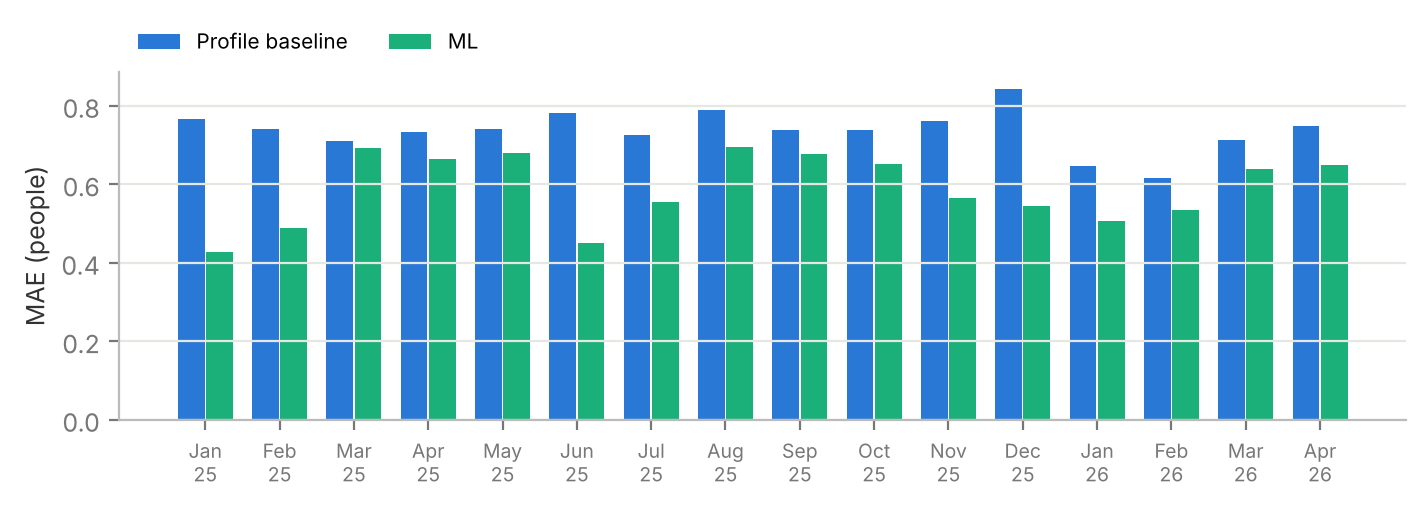

In [4]:
both = pd.concat([val_pred, test_pred]).assign(month=lambda d: d["date"].str[:7])
rows = []
for month, d in both.groupby("month"):
    rows.append({"month": month, "hours": len(d), "semester days": d["in_semester"].mean(),
                 "Profile baseline": evaluate.mae(d["mean_headcount"], d["baseline"]),
                 "ML": evaluate.mae(d["mean_headcount"], d["ml"]),
                 "acc timetable": evaluate.hvac_outcomes(d["mean_headcount"], d["timetable"])["accuracy"],
                 "acc baseline": evaluate.hvac_outcomes(d["mean_headcount"], d["baseline"] >= THR)["accuracy"],
                 "acc ML": evaluate.hvac_outcomes(d["mean_headcount"], d["ml"] >= THR)["accuracy"]})
monthly = pd.DataFrame(rows).set_index("month")
monthly.to_csv(RESULTS / "stage4_monthly.csv")
fig = plots.monthly_mae(monthly)
fig.savefig(FIGURES_DIR / "fig6_monthly_mae.png", facecolor="white")
print(f"ML has lower MAE in {(monthly['ML'] < monthly['Profile baseline']).sum()} of {len(monthly)} months; "
      f"highest accuracy of the three in {(monthly['acc ML'] >= monthly[['acc timetable', 'acc baseline']].max(axis=1)).sum()} months")
monthly.round(3)

## 3. Walk-forward validation
At the start of every month from Jan 2025 to Apr 2026, both forecasts are retrained on **all data before that month** and forecast that month only. This mirrors real use (the model is refreshed as new data arrives) and tests 16 different training/test splits instead of one.

In [5]:
t = time.perf_counter()
wf = robustness.walk_forward(data, [m.strftime("%Y-%m") for m in pd.date_range("2025-01", "2026-04", freq="MS")],
                             {"baseline": ProfileBaseline, "ml": ML})
print(f"16 retrains of each model in {time.perf_counter() - t:.0f} s")
wf_month = wf.groupby("month").apply(lambda d: pd.Series({
    "baseline MAE": evaluate.mae(d["mean_headcount"], d["baseline"]),
    "ML MAE": evaluate.mae(d["mean_headcount"], d["ml"])}), include_groups=False)
wf_total = pd.DataFrame([evaluate.score_forecast(wf, wf["baseline"], "Profile baseline (walk-forward)"),
                         evaluate.score_forecast(wf, wf["ml"], "ML (walk-forward)")]).set_index("approach")
wf_total.to_csv(RESULTS / "stage4_walk_forward.csv")
print(f"ML better in {(wf_month['ML MAE'] < wf_month['baseline MAE']).sum()} of {len(wf_month)} months")
wf_total[["hours", "mae", "rmse", "wasted", "discomfort", "accuracy"]].round(3)

16 retrains of each model in 21 s
ML better in 15 of 16 months


,hours,mae,rmse,wasted,discomfort,accuracy
approach,,,,,,
Profile baseline (walk-forward),31919,0.693,1.332,5712,2487,0.743
ML (walk-forward),31919,0.584,1.241,4156,2722,0.785


## 4. A different model, and different random seeds
**Random forest** (many independent deep trees, averaged) as a second ML model. Gradient boosting here has no random element (no subsampling or early stopping), so changing its seed gives identical results; the random forest *is* random, so 5 seeds show how much results move by chance.

In [6]:
rows = []
for seed in range(5):
    t = time.perf_counter(); rf = RandomForestForecaster(random_state=seed).fit(train); fit_s = time.perf_counter() - t
    rows.append({"model": "Random forest", "seed": seed, "fit_seconds": fit_s,
                 "mae": evaluate.mae(val["mean_headcount"], rf.predict(val))})
    t = time.perf_counter(); gb = ML(random_state=seed).fit(train); fit_s = time.perf_counter() - t
    rows.append({"model": "Gradient boosting", "seed": seed, "fit_seconds": fit_s,
                 "mae": evaluate.mae(val["mean_headcount"], gb.predict(val))})
seeds = pd.DataFrame(rows)
seeds.to_csv(RESULTS / "stage4_seeds.csv", index=False)
seeds.groupby("model")[["mae", "fit_seconds"]].agg(["mean", "min", "max"]).round(4)

mae                 fit_seconds                
                     mean     min     max        mean     min     max
model                                                                
Gradient boosting  0.5946  0.5946  0.5946      0.9904  0.9402  1.0694
Random forest      0.6049  0.6046  0.6057      8.6030  8.4705  8.6635

In [7]:
rf_final = RandomForestForecaster().fit(history)
pd.DataFrame([evaluate.score_forecast(val, RandomForestForecaster().fit(train).predict(val), "Random forest – 2025"),
              evaluate.score_forecast(val, val_pred["ml"], "Gradient boosting – 2025"),
              evaluate.score_forecast(test, rf_final.predict(test), "Random forest – 2026"),
              evaluate.score_forecast(test, test_pred["ml"], "Gradient boosting – 2026")]
             ).set_index("approach")[["mae", "rmse", "wasted", "discomfort", "accuracy"]].round(3)

,mae,rmse,wasted,discomfort,accuracy
approach,,,,,
Random forest – 2025,0.605,1.247,3640,2015,0.772
Gradient boosting – 2025,0.595,1.243,3370,2065,0.780
Random forest – 2026,0.595,1.290,930,623,0.783
Gradient boosting – 2026,0.581,1.283,836,651,0.792


## 5. Input removal
The model is retrained without groups of inputs. A large rise in MAE means that group carries information the rest cannot replace.

In [8]:
recent = ["lag_1d", "lag_7d", "mean_4w", "yesterday_mean"]
variants = {
    "All inputs": features.FEATURES,
    "Without recent occupancy (calendar only)": [f for f in features.FEATURES if f not in recent],
    "Without semester flag": [f for f in features.FEATURES if f != "in_semester"],
    "Without is_weekend": [f for f in features.FEATURES if f != "is_weekend"],
    "Without space": [f for f in features.FEATURES if f != "space"],
    "Recent occupancy + hour only": ["hour_of_day"] + recent,
}
ablation = pd.DataFrame([evaluate.score_forecast(val, ML(features=cols).fit(train).predict(val), name)
                         for name, cols in variants.items()]).set_index("approach")
ablation["mae_change"] = ablation["mae"] - ablation.loc["All inputs", "mae"]
ablation.to_csv(RESULTS / "stage4_input_removal.csv")
ablation[["mae", "mae_change", "wasted", "discomfort", "accuracy"]].round(3)

,mae,mae_change,wasted,discomfort,accuracy
approach,,,,,
All inputs,0.595,0.000,3370,2065,0.780
Without recent occupancy (calendar only),0.708,0.113,4064,2049,0.753
Without semester flag,0.598,0.003,3299,2116,0.781
Without is_weekend,0.595,0.000,3370,2065,0.780
Without space,0.593,-0.002,3401,2047,0.780
Recent occupancy + hour only,0.618,0.023,3775,2109,0.762


## 6. Switch-on threshold: the wasted vs discomfort trade-off (Figure 7)
So far the HVAC switches on when the forecast reaches 1 person. Lowering that level conditions more hours (less discomfort, more waste); raising it does the opposite. The *definition* of an occupied hour stays at 1 person throughout.

The threshold is **chosen on 2025** (highest share of correct decisions) and then applied **once** to 2026.

,wasted,discomfort,wasted_rate,discomfort_rate,accuracy
switch_on_at,,,,,
0.5,10532,207,0.784,0.018,0.566
0.6,8052,537,0.599,0.047,0.653
0.7,6362,873,0.474,0.077,0.708
0.8,5093,1231,0.379,0.109,0.745
0.9,4088,1627,0.304,0.144,0.769
1.0,3370,2065,0.251,0.182,0.780
1.1,2745,2542,0.204,0.224,0.786
1.2,2256,3004,0.168,0.265,0.788
1.3,1841,3525,0.137,0.311,0.783


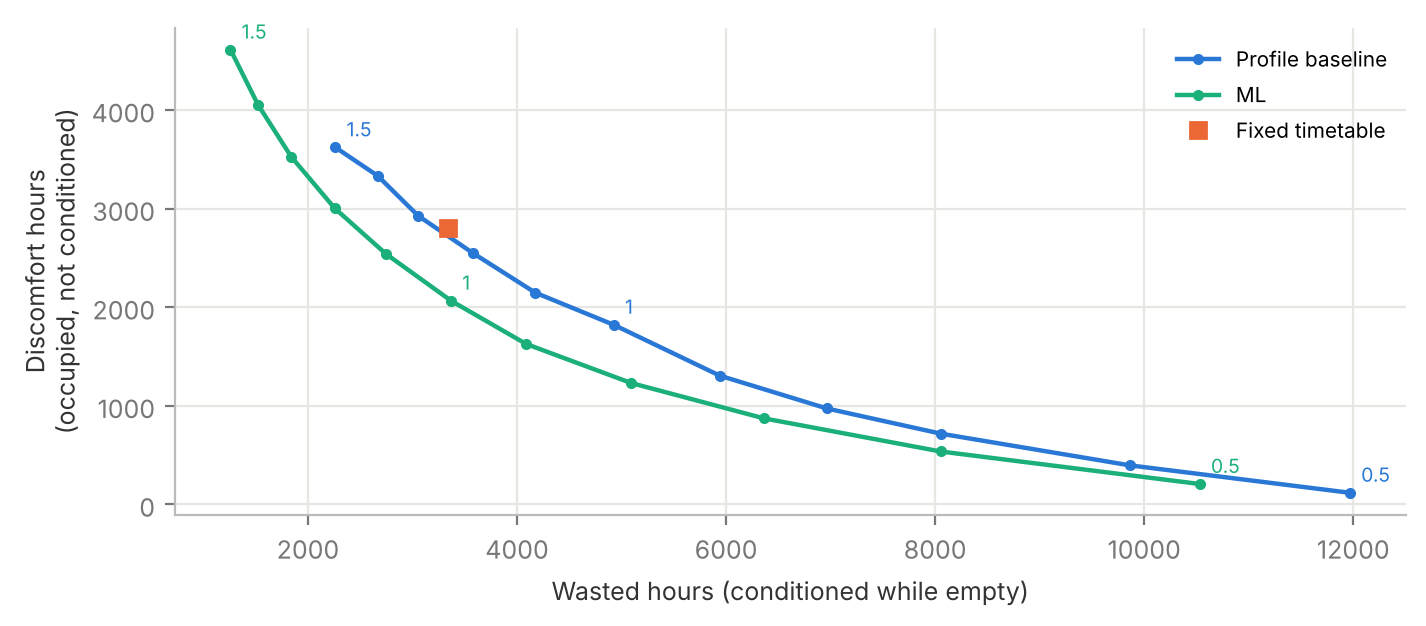

In [9]:
levels = np.round(np.arange(0.5, 1.51, 0.1), 2)
curves = {"Profile baseline": robustness.threshold_curve(val, val_pred["baseline"], levels),
          "ML": robustness.threshold_curve(val, val_pred["ml"], levels)}
tt = evaluate.hvac_outcomes(val["mean_headcount"], val_pred["timetable"])
fig = plots.tradeoff(curves, {"Fixed timetable": (tt["wasted"], tt["discomfort"])})
fig.savefig(FIGURES_DIR / "fig7_threshold_tradeoff.png", facecolor="white")
curve_table = pd.concat(curves, names=["approach"]).reset_index(level=0)
curve_table.to_csv(RESULTS / "stage4_threshold_curve.csv", index=False)
curves["ML"].set_index("switch_on_at")[["wasted", "discomfort", "wasted_rate", "discomfort_rate", "accuracy"]].round(3)

In [10]:
best_ml = curves["ML"].loc[curves["ML"]["accuracy"].idxmax(), "switch_on_at"]
best_base = curves["Profile baseline"].loc[curves["Profile baseline"]["accuracy"].idxmax(), "switch_on_at"]
print(f"Best switch-on level on 2025: ML {best_ml:g} people, baseline {best_base:g} people")
chosen = pd.DataFrame([
    evaluate.score_schedule(test, test_pred["timetable"], "Fixed timetable"),
    {**evaluate.score_forecast(test, test_pred["baseline"], f"Baseline, switch on at {best_base:g}"),
     **evaluate.hvac_outcomes(test["mean_headcount"], test_pred["baseline"] >= best_base)},
    evaluate.score_forecast(test, test_pred["ml"], "ML, switch on at 1 (Stage 3)"),
    {**evaluate.score_forecast(test, test_pred["ml"], f"ML, switch on at {best_ml:g}"),
     **evaluate.hvac_outcomes(test["mean_headcount"], test_pred["ml"] >= best_ml)},
]).set_index("approach")
chosen.to_csv(RESULTS / "stage4_threshold_on_test.csv")
chosen[["wasted", "discomfort", "wasted_rate", "discomfort_rate", "accuracy"]].round(3)

Best switch-on level on 2025: ML 1.2 people, baseline 1.5 people


,wasted,discomfort,wasted_rate,discomfort_rate,accuracy
approach,,,,,
Fixed timetable,1016,681,0.261,0.208,0.763
"Baseline, switch on at 1.5",627,1004,0.161,0.307,0.772
"ML, switch on at 1 (Stage 3)",836,651,0.215,0.199,0.792
"ML, switch on at 1.2",589,897,0.151,0.274,0.792


**Different definition of "occupied".** If an occupied hour were defined as ≥ 0.5 or ≥ 1.5 people (and the forecasts switched on at the same level), does the ranking of the three approaches change?

In [11]:
rows = []
for occ in [0.5, 1.0, 1.5]:
    for name, on in [("Timetable", val_pred["timetable"]), ("Baseline", val_pred["baseline"] >= occ), ("ML", val_pred["ml"] >= occ)]:
        rows.append({"occupied at ≥": occ, "approach": name, **evaluate.hvac_outcomes(val["mean_headcount"], on, occ)})
occ_sens = pd.DataFrame(rows)
occ_sens.to_csv(RESULTS / "stage4_occupied_definition.csv", index=False)
occ_sens.pivot(index="approach", columns="occupied at ≥", values=["accuracy", "wasted", "discomfort"]).round(3)

accuracy                wasted                 discomfort  \
occupied at ≥      0.5    1.0    1.5     0.5     1.0     1.5        0.5   
approach                                                                  
Baseline         0.676  0.727  0.774  7690.0  4927.0  3912.0      323.0   
ML               0.717  0.780  0.812  6421.0  3370.0  2447.0      580.0   
Timetable        0.719  0.752  0.728  1507.0  3339.0  5425.0     5459.0   

                               
occupied at ≥     1.0     1.5  
approach                       
Baseline       1821.0  1682.0  
ML             2065.0  2212.0  
Timetable      2807.0  1305.0

## 7. How much training history is needed?
Train on only the last 3, 6 or 9 months before 2025, or on everything (from Nov 2023), and score on 2025.

In [12]:
rows = []
for months in [3, 6, 9, None]:
    start = "2000-01-01" if months is None else (pd.Timestamp("2025-01-01") - pd.DateOffset(months=months)).strftime("%Y-%m-%d")
    tr = train[train["date"] >= start]
    label = "all (from " + train["date"].min() + ")" if months is None else f"last {months} months"
    rows.append({"training data": label, "hours": len(tr),
                 "baseline MAE": evaluate.mae(val["mean_headcount"], ProfileBaseline().fit(tr).predict(val)),
                 "ML MAE": evaluate.mae(val["mean_headcount"], ML().fit(tr).predict(val))})
amount = pd.DataFrame(rows).set_index("training data")
amount.to_csv(RESULTS / "stage4_training_amount.csv")
amount.round(3)

,hours,baseline MAE,ML MAE
training data,,,
last 3 months,7544,0.751,0.603
last 6 months,16200,0.824,0.611
last 9 months,23941,0.769,0.606
all (from 2023-11-24),29069,0.753,0.595


## 8. A room the model has never seen (leave-one-space-out)
For each space with 2025 data, the ML model is trained on the **other** spaces only (without the `space` input, which would be meaningless for a new room) and forecasts the held-out space in 2025. Its recent-occupancy inputs still come from the new room's own sensor. The profile baseline cannot do this at all: it needs history of the room itself.

In [13]:
rows = []
no_space = [f for f in features.FEATURES if f != "space"]
for space in sorted(val["space"].unique()):
    v = val[val["space"] == space]
    other = ML(features=no_space).fit(train[train["space"] != space])
    rows.append({"space": space,
                 "ML trained on other spaces": evaluate.mae(v["mean_headcount"], other.predict(v)),
                 "ML trained on all (Stage 3)": evaluate.mae(v["mean_headcount"], val_pred.loc[v.index, "ml"]),
                 "Profile baseline (own history)": evaluate.mae(v["mean_headcount"], val_pred.loc[v.index, "baseline"])})
transfer = pd.DataFrame(rows).set_index("space")
transfer.to_csv(RESULTS / "stage4_transfer.csv")
transfer.round(3)

,ML trained on other spaces,ML trained on all (Stage 3),Profile baseline (own history)
space,,,
G.20 Breakout,1.088,1.111,1.346
G.25 MSM Lab,0.511,0.530,0.789
Space A,0.480,0.455,0.554
Space B,0.449,0.423,0.466


## 9. Where does it go wrong?
### Bias by hour of day (Figure 8)
Average of (forecast − measured). Above zero = over-forecast (risk of wasted energy); below = under-forecast (risk of discomfort).

hour_of_day,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Profile baseline,0.10,0.07,0.12,0.13,0.09,0.09,0.12,-0.06,0.09,0.19,...,0.43,0.63,0.52,0.41,0.22,0.11,0.05,0.08,0.04,0.08
ML,-0.02,0.01,0.03,0.04,0.06,0.07,0.04,-0.09,0.03,0.05,...,0.07,0.09,0.12,0.09,0.01,-0.04,-0.04,0.02,0.00,0.01


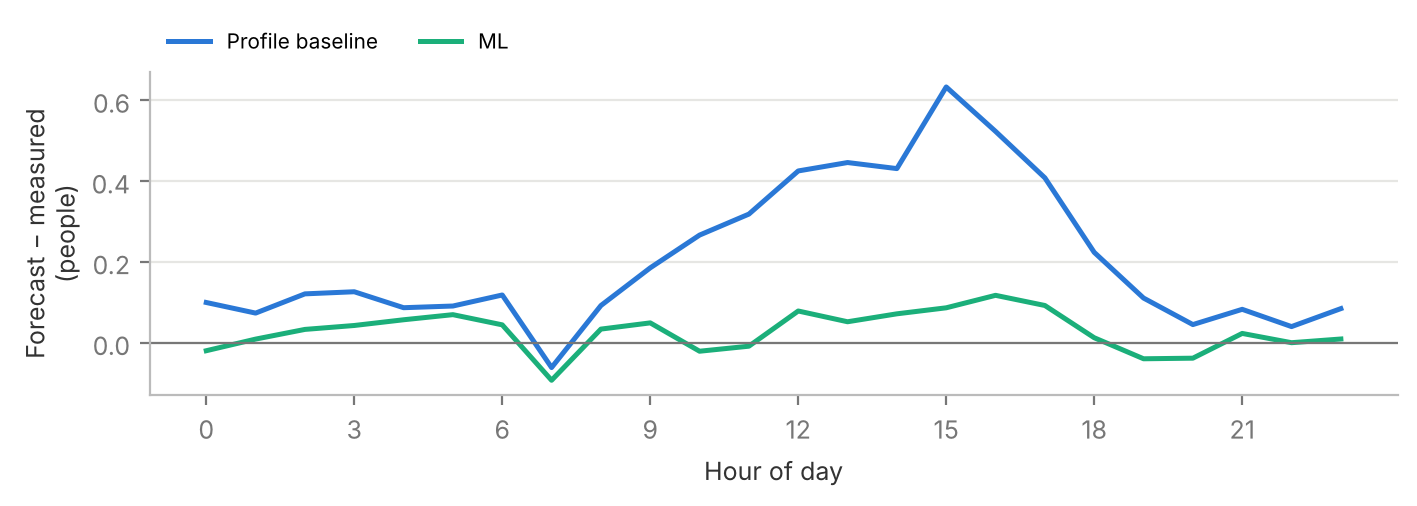

In [14]:
bias = pd.DataFrame({"Profile baseline": (val_pred["baseline"] - val_pred["mean_headcount"]).groupby(val_pred["hour_of_day"]).mean(),
                     "ML": (val_pred["ml"] - val_pred["mean_headcount"]).groupby(val_pred["hour_of_day"]).mean()})
bias.to_csv(RESULTS / "stage4_bias_by_hour.csv")
fig = plots.bias_by_hour(bias)
fig.savefig(FIGURES_DIR / "fig8_bias_by_hour.png", facecolor="white")
bias.T.round(2)

### Special days and conditions (2025 and 2026 together)

In [15]:
both["holiday"] = robustness.public_holidays(both["date"])
groups = {
    "All hours": both.index == both.index,
    "Semester weekdays": (both["in_semester"] == 1) & (both["day_type"] == "Weekday") & ~both["holiday"],
    "Non-semester weekdays": (both["in_semester"] == 0) & (both["day_type"] == "Weekday") & ~both["holiday"],
    "Weekends": both["day_type"] == "Weekend",
    "Public holidays": both["holiday"],
    "Event hours (≥30 people)": both["is_event"],
    "Yesterday's same hour missing (sensor gap)": both["lag_1d"].isna(),
    "Yesterday's same hour present": both["lag_1d"].notna(),
}
rows = []
for name, mask in groups.items():
    d = both[mask]
    rows.append({"condition": name, "hours": len(d), "mean measured": d["mean_headcount"].mean(),
                 "baseline MAE": evaluate.mae(d["mean_headcount"], d["baseline"]),
                 "ML MAE": evaluate.mae(d["mean_headcount"], d["ml"]),
                 "ML bias": (d["ml"] - d["mean_headcount"]).mean()})
conditions = pd.DataFrame(rows).set_index("condition")
conditions.to_csv(RESULTS / "stage4_conditions.csv")
conditions.round(3)

,hours,mean measured,baseline MAE,ML MAE,ML bias
condition,,,,,
All hours,31919,1.258,0.736,0.592,0.015
Semester weekdays,12238,1.624,0.776,0.700,0.040
Non-semester weekdays,11623,1.215,0.810,0.567,-0.050
Weekends,7296,0.754,0.527,0.442,0.040
Public holidays,890,0.821,0.907,0.610,0.347
Event hours (≥30 people),34,24.911,22.270,22.146,-22.146
Yesterday's same hour missing (sensor gap),5203,0.871,0.610,0.458,-0.048
Yesterday's same hour present,26716,1.334,0.761,0.618,0.027


## 10. What if missing hours were empty?
Notebooks 01–03 treat an hour with no readings as **unknown**. Because the sensor only writes a row when something changes, a silent hour may instead mean nobody was there. Here every missing hour on a day when that sensor was working is filled with 0 people; inputs are rebuilt and both forecasts retrained and rescored.

In [16]:
filled = robustness.fill_missing_as_empty(hourly)
print(f"{filled['imputed'].sum():,} hours added as empty "
      f"({filled['imputed'].mean():.1%} of the filled table); "
      f"share at 10 pm–6 am: {filled.loc[filled['imputed'], 'hour_of_day'].isin([22, 23, 0, 1, 2, 3, 4, 5]).mean():.0%}")
fdata = features.add_features(filled)
fs = evaluate.chronological_split(fdata)
ftrain, fhist = fs["train"], pd.concat([fs["train"], fs["validation"]])
rows = []
for period, d, hist in [("2025", fs["validation"], ftrain), ("2026", fs["test"], fhist)]:
    b, m = ProfileBaseline().fit(hist).predict(d), ML().fit(hist).predict(d)
    rows += [evaluate.score_schedule(d, timetable.schedule(d), f"{period} Timetable"),
             evaluate.score_forecast(d, b, f"{period} Baseline"),
             evaluate.score_forecast(d, m, f"{period} ML")]
missing_empty = pd.DataFrame(rows).set_index("approach")
missing_empty.to_csv(RESULTS / "stage4_missing_as_empty.csv")
missing_empty[["hours", "mae", "wasted", "discomfort", "accuracy"]].round(3)

23,546 hours added as empty (27.9% of the filled table); share at 10 pm–6 am: 62%


,hours,mae,wasted,discomfort,accuracy
approach,,,,,
2025 Timetable,34866,NaN,3961,2807,0.806
2025 Baseline,34866,0.645,4796,2351,0.795
2025 ML,34866,0.512,3081,2713,0.834
2026 Timetable,10725,NaN,1249,681,0.820
2026 Baseline,10725,0.600,1390,684,0.807
2026 ML,10725,0.494,767,902,0.844


## 11. Hour-ahead forecast (comparison only)
If the forecast were made at the start of each hour, the previous hour's headcount (`lag_1h`) would be known. This shows how much accuracy the day-ahead design gives up in exchange for being able to plan a whole day of pre-conditioning.

In [17]:
hdata = robustness.add_hour_ahead_lag(data)
hs = evaluate.chronological_split(hdata)
hour_ahead = ML(features=features.FEATURES + ["lag_1h"])
rows = []
for period, d, hist in [("2025", hs["validation"], hs["train"]), ("2026", hs["test"], pd.concat([hs["train"], hs["validation"]]))]:
    day_ahead_pred = val_pred["ml"] if period == "2025" else test_pred["ml"]
    rows += [evaluate.score_forecast(d, day_ahead_pred.loc[d.index], f"{period} day-ahead ML"),
             evaluate.score_forecast(d, hour_ahead.fit(hist).predict(d), f"{period} hour-ahead ML")]
horizon = pd.DataFrame(rows).set_index("approach")
horizon.to_csv(RESULTS / "stage4_hour_ahead.csv")
horizon[["mae", "rmse", "wasted", "discomfort", "accuracy"]].round(3)

,mae,rmse,wasted,discomfort,accuracy
approach,,,,,
2025 day-ahead ML,0.595,1.243,3370,2065,0.780
2025 hour-ahead ML,0.480,1.052,2129,2074,0.830
2026 day-ahead ML,0.581,1.283,836,651,0.792
2026 hour-ahead ML,0.485,1.145,559,589,0.840


## 12. Timing and profiling
Wall-clock time of each step on this computer, then how model training time grows with the amount of data, then a profile of where the time goes in the slowest step.

In [18]:
def timed(fn, repeats=3):
    best = float("inf")
    for _ in range(repeats):
        t = time.perf_counter(); out = fn(); best = min(best, time.perf_counter() - t)
    return best, out

steps = {}
steps["Load hourly table (CSV)"], _ = timed(lambda: clean.load_hourly(PROCESSED_DIR / "occupancy_hourly.csv"))
steps["Build model inputs"], _ = timed(lambda: features.add_features(hourly))
steps["Fit profile baseline"], base_m = timed(lambda: ProfileBaseline().fit(history))
steps["Fit gradient boosting"], ml_m = timed(lambda: ML().fit(history))
steps["Fit random forest"], _ = timed(lambda: RandomForestForecaster().fit(history), repeats=1)
steps["Forecast one day, all spaces (ML)"], _ = timed(lambda: ml_m.predict(test[test["date"] == "2026-03-10"]), repeats=20)
steps["Forecast whole 2026 test (ML)"], _ = timed(lambda: ml_m.predict(test))
timing = pd.Series(steps, name="seconds").to_frame()
timing.to_csv(RESULTS / "stage4_timing.csv")
print("Raw-data pipeline (notebook 01 / python -m occupancy.pipeline): about 100 s, run once.")
timing.round(4)

Raw-data pipeline (notebook 01 / python -m occupancy.pipeline): about 100 s, run once.


,seconds
Load hourly table (CSV),0.5192
Build model inputs,0.0945
Fit profile baseline,0.0121
Fit gradient boosting,1.3726
Fit random forest,17.8220
"Forecast one day, all spaces (ML)",0.0096
Forecast whole 2026 test (ML),0.0535


In [19]:
rows = []
for frac in [0.25, 0.5, 1.0]:
    sub = history.iloc[: int(len(history) * frac)]
    secs, _ = timed(lambda: ML().fit(sub))
    rows.append({"training hours": len(sub), "fit seconds": secs})
scaling = pd.DataFrame(rows)
scaling["seconds per 10,000 hours"] = scaling["fit seconds"] / scaling["training hours"] * 1e4
scaling.round(3)

,training hours,fit seconds,"seconds per 10,000 hours"
0,13457,0.851,0.633
1,26914,0.945,0.351
2,53828,1.362,0.253


In [20]:
prof = cProfile.Profile()
prof.enable(); ML().fit(history); prof.disable()
s = io.StringIO(); pstats.Stats(prof, stream=s).sort_stats("cumulative").print_stats(8)
print("\n".join(s.getvalue().splitlines()[:30]))

         368496 function calls (349706 primitive calls) in 1.531 seconds

   Ordered by: cumulative time
   List reduced from 1274 to 8 due to restriction <8>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
      3/2    0.000    0.000    1.531    0.765 /usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py:3786(run_code)
      3/2    0.000    0.000    1.531    0.765 {built-in method builtins.exec}
        1    0.000    0.000    1.520    1.520 /home/claude/mma3001-occupancy-forecasting/src/occupancy/models.py:125(fit)
      4/1    0.013    0.003    1.518    1.518 /usr/local/lib/python3.13/dist-packages/sklearn/base.py:1381(wrapper)
        1    0.045    0.045    1.109    1.109 /usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_hist_gradient_boosting/gradient_boosting.py:393(fit)
      300    0.005    0.000    0.895    0.003 /usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_hist_gradient_boosting/grower.py:383(grow)
     9000    0

## 13. Observations
**The gain is real, but its size depends on the time of year.**
* **Not luck.** Resampling days 2,000 times, the ML–baseline MAE difference stays below zero every time: −0.16 people in 2025 (95 % interval −0.175 to −0.142) and −0.10 in 2026 (−0.118 to −0.077). The ML forecast has lower MAE in all 16 months, and the best HVAC accuracy of the three approaches in 14 of 16.
* **Day by day it is a modest edge, not a landslide.** For a given space and day, the ML makes more correct on/off decisions than the baseline on about half of days, the same on a quarter to a third, and fewer on about one day in five.
* **Biggest gain outside semester.** In Jan, Jun, Nov and Dec 2025 the ML's MAE is 26–44 % lower than the baseline's. During semester months it is only 3–13 % lower (e.g. Mar 2025: 0.69 vs 0.71). The baseline averages busy and quiet periods together, so it over-forecasts holidays (Figure 8 shows it over-forecasts afternoons by up to 0.6 people on average). The ML's recent-occupancy inputs and semester flag tell it which kind of week it is in.
* **Walk-forward (retrained every month) gives the same picture:** MAE 0.584 vs 0.693, accuracy 78.5 % vs 74.3 %, ML better in 15 of 16 months.
* **Model choice and randomness don't change the conclusion.** A random forest scores nearly the same (MAE 0.605 in 2025, 0.595 in 2026) but takes 9–18 s to train instead of about 1 s. Gradient boosting with no subsampling is deterministic (identical results for every seed); the forest moves by only ±0.001 people across 5 seeds.
* **Recent occupancy is the input that matters.** Removing it raises MAE from 0.595 to 0.708 and cuts accuracy from 78.0 % to 75.3 %. Removing `is_weekend`, `space` or the semester flag changes MAE by 0.003 or less (the information is covered by other inputs).
* **Threshold trade-off (Figure 7).** For every switch-on level, the ML curve sits below and left of the baseline curve: fewer wasted *and* fewer discomfort hours. The fixed timetable sits on the baseline curve, so the ML beats it too: at a level of 1.1 people the ML has fewer wasted (2,745 vs 3,339) *and* fewer discomfort hours (2,542 vs 2,807) than the timetable. Accuracy is flat between 1.0 and 1.3 (78.0–78.8 %); the level chosen on 2025 (1.2) gave the same 2026 accuracy as 1.0 (79.2 %) but swapped 247 fewer wasted hours for 246 more discomfort hours. **The best level is therefore a choice about energy cost versus comfort, not something accuracy alone decides.** The ML stays most accurate if "occupied" is defined as 0.5 or 1.5 people instead of 1.
* **Little history needed.** Training on only the last 3 months of 2024 gives MAE 0.603, almost the same as all 14 months (0.595).
* **Works in an unseen room.** Trained on the other spaces only, the ML forecasts each held-out space about as well as the full model (e.g. G.25: 0.511 vs 0.530) and much better than that room's own profile baseline. This works because the recent-occupancy inputs come from the new room's own sensor.
* **Where it fails.** One-off events cannot be forecast: in the 34 hours with ≥30 people, both forecasts miss by about 22 people. On public holidays the ML over-forecasts by 0.35 people on average, because public holidays are not one of its inputs; adding a holiday flag is a simple improvement. Semester weekdays are the hardest normal hours (MAE 0.70).
* **Missing hours as empty.** If silent hours on working days are counted as empty (23,546 hours added, 62 % of them overnight), every approach scores higher accuracy, and the ML is still best (83.4 % in 2025, 84.4 % in 2026 vs 79.5–82.0 % for the others). The conclusion does not depend on this assumption.
* **Day-ahead vs hour-ahead.** Knowing the previous hour lowers MAE from 0.595 to 0.480 and raises accuracy from 78 % to 83 %. This is the price of planning a whole day ahead. A practical system could combine both: plan the day at midnight, then correct each hour.
* **Speed.** Building inputs takes 0.1 s, training about 1.4 s on 54,000 hours, and forecasting a whole day for all spaces under 0.01 s. Most training time is spent in scikit-learn's tree-growing routine (`split_next`). Training time grows more slowly than the data (4× the data took less than twice the time). The slow step is reading the 1.6 GB raw file (about 100 s), which only happens once.
